# **Описание файла**

В данном ноутбуке реализован этап построения базовой (baseline) модели для задачи регрессии годовых медицинские расходы клиентов. Цель этапа — сформировать воспроизводимый пайплайн предобработки данных и получить объективный ориентир качества, относительно которого в дальнейшем будут оцениваться улучшения (новые признаки, ансамбли, подбор гиперпараметров).

На текущем этапе решаются следующие задачи:

- **Предобработка данных**: очистка от очевидных аномалий, обработка пропусков, приведение типов и кодирование категориальных признаков с сохранением семантики (в том числе бинарных признаков).
- **Подготовка выборок**: формирование обучающей и тестовой подвыборок с учётом дисбаланса классов, применение стратификации по целевой переменной, а при необходимости — кросс-валидация с `StratifiedKFold`.
- **Построение baseline-моделей**: реализация простых, но информативных моделей, позволяющих оценить принципиальную предсказуемость целевой переменной на имеющихся признаках:
  - логистическая регрессия (`LogisticRegression`) как интерпретируемая базовая модель;
  - простое дерево решений небольшой глубины (`DecisionTreeClassifier`) для быстрой оценки нелинейностей.
- **Оценка качества**: расчёт ключевых метрик (MAE, MSE, RMSE, R1), анализ матрицы ошибок и сравнение результатов моделей между собой и с наивной стратегией.

Полученные результаты будут использованы как точка отсчёта для последующих экспериментов: добавления новых признаков, применения методов борьбы с дисбалансом (SMOTE, `class_weight`), а также более сложных моделей (RandomForest, LGBMClassifier). Все этапы реализованы с учётом воспроизводимости: зафиксированы `random_state`, последовательность шагов предобработки и схема валидации.


# **Импорт основных библиотек**

In [1]:
# импорт модулей/библиотек для обработки данных
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, KFold
from sklearn.metrics import roc_auc_score, f1_score, classification_report
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from lightgbm import LGBMRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.base import BaseEstimator, TransformerMixin
import seaborn as sns
from my_def_and_plot import *
import random
from scipy.stats import randint, uniform, loguniform
import lightgbm as lgb
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.tree import DecisionTreeRegressor

from sklearn.linear_model import Ridge
from scipy.stats import uniform, randint
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso


In [2]:
# импорт необходимого окружения для визуализации
# отключим предупреждения Anaconda
import warnings
warnings.simplefilter('ignore')

# будем отображать графики прямо в jupyter'e
%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt
#графики в svg выглядят более четкими
%config InlineBackend.figure_format = 'svg' 

#увеличим дефолтный размер графиков
from pylab import rcParams
rcParams['figure.figsize'] = 8, 5
import pandas as pd

In [3]:
# фиксируем состояние генератора псевдослучайных чисел. Это необходимо, чтобы результаты модели не менялись с каждым новым запуском 
SEED = 42 # можно указать любое число
np.random.seed(SEED)
random.seed(SEED)

# **1. Препроцессинг данных**

**Препроцессинг данных можно разделить на две основные категории:**

* Общие преобразования – применяются ко всему датасету до разделения на train и test.
* Индивидуальные преобразования – выполняются отдельно для тренировочной и тестовой выборок.

`Почему такое разделение необходимо?`

Некоторые преобразования требуют расчета статистик (например, замена пропусков медианой, стандартизация, частотное кодирование) или даже обучения вспомогательных моделей (например, KNN для импутации пропущенных значений). Если применить такие преобразования ко всему датасету до разделения, это приведет к data leakage (утечке данных).

`Что такое data leakage и чем он опасен?`

Data leakage возникает, когда информация из тестового набора неявно влияет на preprocessing тренировочных данных (например, при расчете среднего или обучении encoder'а). В результате:

Модель получает доступ к данным, которых не должно "знать" в реальных условиях;
Оценки качества становятся завышенными, но на новых данных модель работает хуже.
Как избежать утечки данных?

Сначала разделять данные на train и test (или использовать кросс-валидацию).
Обучать preprocessing-алгоритмы (импутеры, энкодеры, скейлеры) только на train.
Применять обученные преобразования к test, без пересчета статистик.
Крайне рекомендуется использовать пайплайны (например, sklearn.pipeline.Pipeline), которые автоматически следят за корректным порядком преобразований.

`Какие преобразования можно применять ко всему датасету?`

Те, что не зависят от статистик и не требуют обучения:

* Удаление дубликатов;
* Исправление очевидных аномалий (например, отрицательный возраст);
* Разовые преобразования (изменение формата даты, переименование столбцов);
* Фильтрация строк/столбцов, не связанная с целевой переменной;
* Такой подход помогает избежать дублирования кода, сохраняя при этом валидность эксперимента.

## **1.1 Общие преобразования**

In [4]:
# выгрузка данных
df = pd.read_csv('medical_insurance.csv')
# создадим независимую копию исходного DataFrame df
df_preprocessed = df.copy()

# удаление признков с мультиколлинеарностью


Обнаружена мультиколлинеарность между входными признаками:

* `annual_premium`(Годовой взнос) и `monthly_premium`(Ежемесячный взнос), но они должны быть удалены оба;
* `diabetes`(Диабет) и `hba1c`(Гликированный гемоглобин);
* `is_high_risk`(Высокий риск) и `risk_score`(Оценка риска).

**Исключение признаков с риском утечки данных (Data Leakage)**

Для обеспечения корректности прогноза целевой переменной annual_medical_cost из матрицы признаков были исключены переменные, функционально связанные с целевой величиной или используемые для её расчёта.

**В частности, удалены следующие признаки:**

* claims_count, avg_claim_amount: их произведение напрямую аппроксимирует сумму медицинских расходов, что приводит к «подглядыванию» в целевую переменную;
* risk_score: представляет собой внутреннюю оценку риска страховой компании, которая уже учитывает ожидаемые выплаты; использование этого признака делает задачу тривиальной;
* annual_premium, monthly_premium: страховые премии формируются на основе оценки рисков и ожидаемых расходов, их использование нарушает причинно-следственную логику прогноза;

После исключения указанных признаков модель вынуждена опираться на демографические, медицинские и поведенческие характеристики клиентов, что позволяет выявить реальные закономерности влияния факторов на медицинские расходы.



In [5]:
# признаки, которые хотели удалить, но из-за отсутствия спецификации данных удалили только некоторые...
# удаление признков с мультиколлинеарностью `annual_premium`,`monthly_premium`, `hba1c` и `is_high_risk`...
list_delete = [
    'claims_count',         
    'avg_claim_amount',      
    'risk_score',           
    'annual_premium',        
    'monthly_premium',        
    'total_claims_paid',
    'hba1c',
    'is_high_risk',
    'dependents'      
]

In [6]:
# удаление признков с мультиколлинеарностью `annual_premium`,`monthly_premium`, `hba1c` и `is_high_risk`...
''' list_delete = [              
    'annual_premium',        
    'monthly_premium',
    'risk_score', 
    'hba1c',
    'is_high_risk',
    'dependents'   
] '''

df_preprocessed = df_preprocessed.drop(list_delete, axis=1)

### **1.1.1 Работа по признаку alcohol_freq**

In [7]:
# количесвто пропусков в признаке alcohol_freq
df_preprocessed['alcohol_freq'].isna().sum()

30083

In [8]:
# уникальные значения признак alcohol_freq
df_preprocessed['alcohol_freq'].value_counts()

alcohol_freq
Occasional    45078
Weekly        19833
Daily          5006
Name: count, dtype: int64

Считаем, что пропуски не случайные и их надо заполнить значением Occasional (ибо человек иногда все-таки выпивает)...

In [9]:
# замена пропуска наиболее логичным значением
df_preprocessed['alcohol_freq'].fillna('Occasional', inplace=True)
# количесвто пропусков в признаке alcohol_freq
df_preprocessed['alcohol_freq'].isna().sum()

0

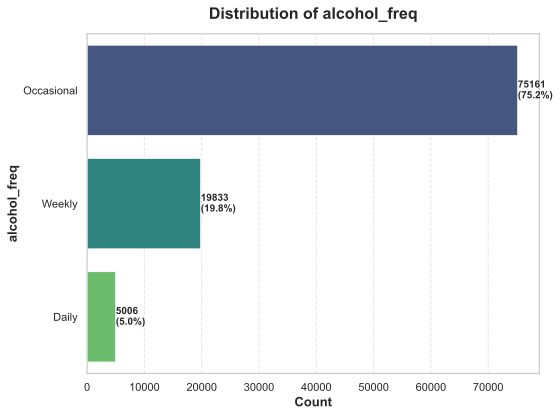

Статистика для 'alcohol_freq':
  Unique categories: 3
  Total count: 100000

Top categories:
  Occasional: 75161 (75.2%)
  Weekly: 19833 (19.8%)
  Daily: 5006 (5.0%)


In [10]:
# воспользуемся столбчатой диаграммой для визуализации
plot_bar_categorical(df_preprocessed,'alcohol_freq')

* нет «микрокатегорий»: все группы достаточно крупные (минимум 5 %), поэтому объединять в «Other» не нужно;
* для alcohol_freq лучше всего порядковое (ordinal) кодирование, а не One‑Hot.

### **1.1.2 Работа по признаку age**

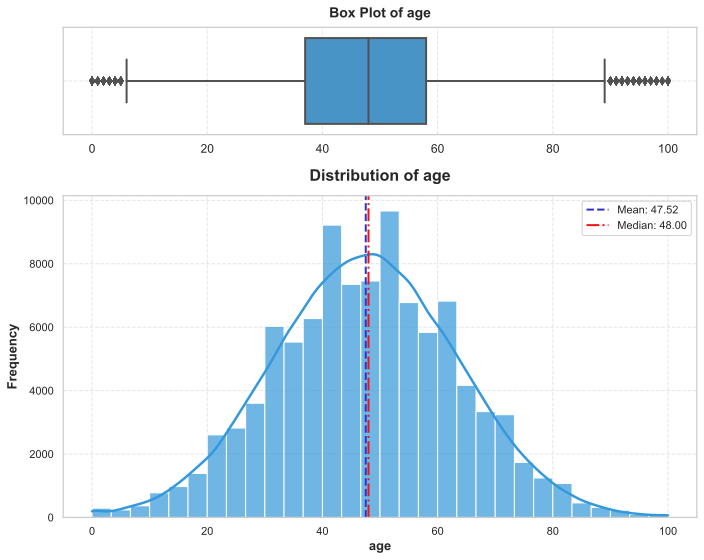

Статистика для 'age':
  Mean:   47.52
  Median: 48.00
  Std:    15.99
  Min:    0.00
  Max:    100.00
  Count:  100000
  Q1:     37.00
  Q3:     58.00
  IQR:    21.00


In [11]:
# до удаления клиентов с возрастом моложе 18 лет
plot_hist_numeric(df_preprocessed, 'age')

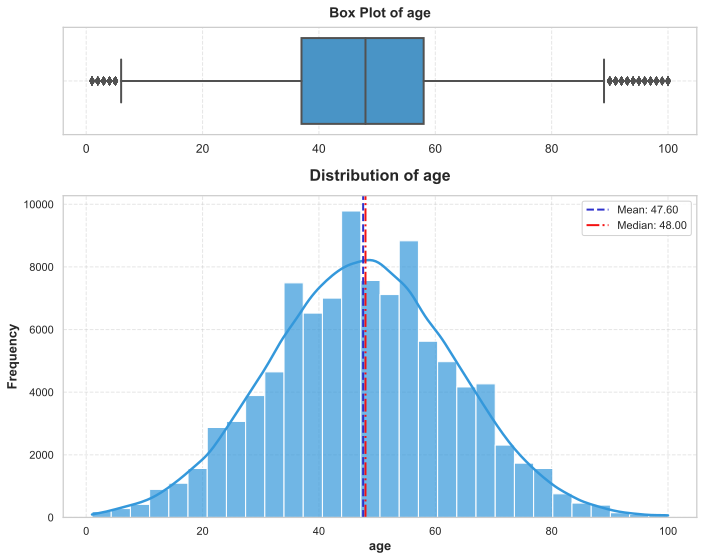

Статистика для 'age':
  Mean:   47.60
  Median: 48.00
  Std:    15.88
  Min:    1.00
  Max:    100.00
  Count:  99835
  Q1:     37.00
  Q3:     58.00
  IQR:    21.00


In [12]:
# удаляем выбросы
df_preprocessed = df_preprocessed[df_preprocessed['age']!=0]
# после удаления клиентов с возрастом моложе 18 лет
plot_hist_numeric(df_preprocessed, 'age')

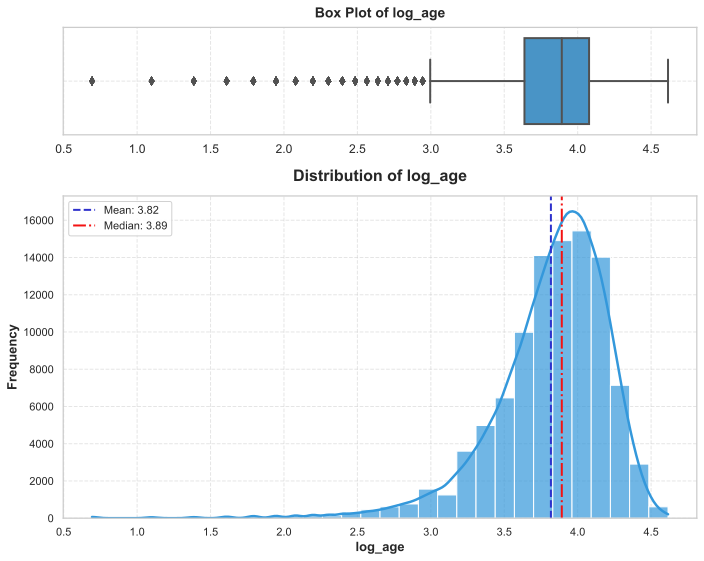

Статистика для 'log_age':
  Mean:   3.82
  Median: 3.89
  Std:    0.40
  Min:    0.69
  Max:    4.62
  Count:  99835
  Q1:     3.64
  Q3:     4.08
  IQR:    0.44


In [13]:
# логарифмирование признака 
df_preprocessed['log_age'] = np.log1p(df_preprocessed['age'])
# удалим duration из датафремйа, чтоб нивелировать перекос
df_preprocessed = df_preprocessed.drop(columns=['age'])
# вывод гистограммы
plot_hist_numeric(df_preprocessed, 'log_age')

* Удалили клиентов моложе 18 лет (считаем, что клиент должен работать => клиент должен быть страше 18 лет);
* Видим перекос вправо, проводим логарифмирование и добавление новго признака (с удалением исходного age).

### **1.1.3 Работа по признаку annual_medical_cost**

--- Статистика для 'annual_medical_cost' ---


count    99835.000000
mean      3010.882841
std       3128.528983
min         55.550000
25%       1175.865000
50%       2083.530000
75%       3709.475000
max      65724.900000
Name: annual_medical_cost, dtype: float64

Axes(0.115466,0.0396;0.859784x0.851133)


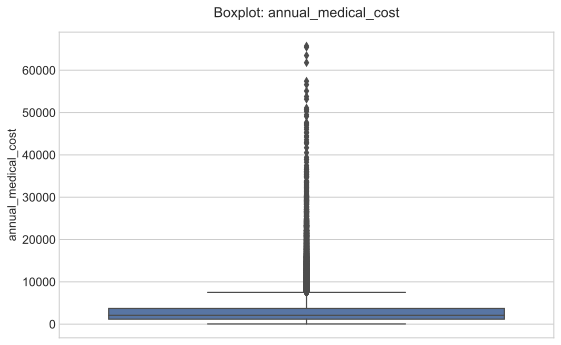

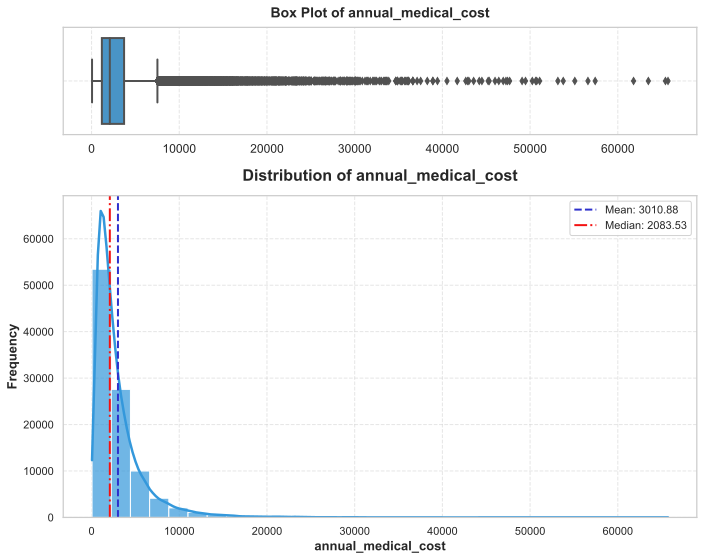

Статистика для 'annual_medical_cost':
  Mean:   3010.88
  Median: 2083.53
  Std:    3128.53
  Min:    55.55
  Max:    65724.90
  Count:  99835
  Q1:     1175.86
  Q3:     3709.48
  IQR:    2533.61
None


In [14]:
# вывод боксплота до логарифмирования для признака
print(plot_box_and_describe_single(df_preprocessed, 'annual_medical_cost'))
# гистограмма income до логарифмирование
print(plot_hist_numeric(df_preprocessed, 'annual_medical_cost'))

In [15]:
df_preprocessed = df_preprocessed[df_preprocessed['annual_medical_cost'] < 6500]

--- Статистика для 'annual_medical_cost' ---


count    90700.000000
mean      2260.176114
std       1471.242719
min         55.550000
25%       1104.220000
50%       1887.310000
75%       3119.102500
max       6499.480000
Name: annual_medical_cost, dtype: float64

Axes(0.103747,0.0396;0.871503x0.851133)


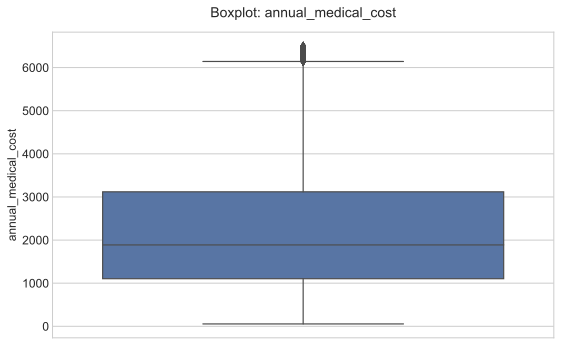

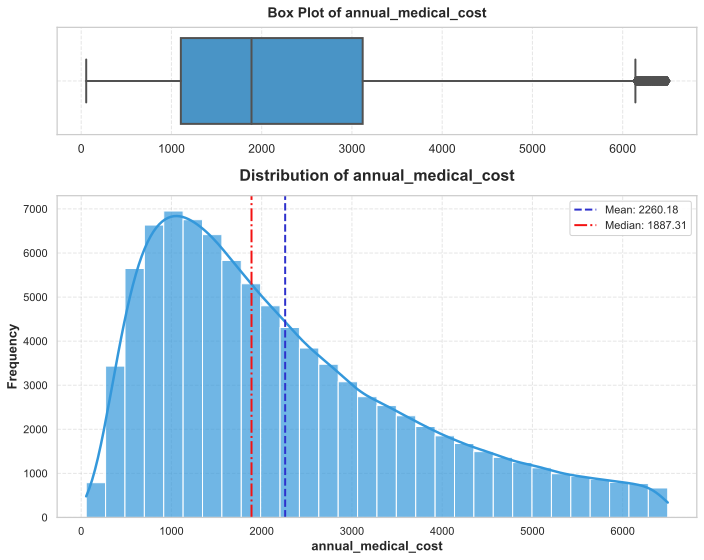

Статистика для 'annual_medical_cost':
  Mean:   2260.18
  Median: 1887.31
  Std:    1471.24
  Min:    55.55
  Max:    6499.48
  Count:  90700
  Q1:     1104.22
  Q3:     3119.10
  IQR:    2014.88
None


In [16]:
# вывод боксплота до логарифмирования для признака
print(plot_box_and_describe_single(df_preprocessed, 'annual_medical_cost'))
# гистограмма income до логарифмирование
print(plot_hist_numeric(df_preprocessed, 'annual_medical_cost'))

### **1.1.3 Работа по признаку income**

--- Статистика для 'income' ---


count    9.070000e+04
mean     4.994833e+04
std      4.700102e+04
min      1.100000e+03
25%      2.110000e+04
50%      3.620000e+04
75%      6.230000e+04
max      1.061800e+06
Name: income, dtype: float64

Axes(0.0857396,0.0396;0.88951x0.851133)


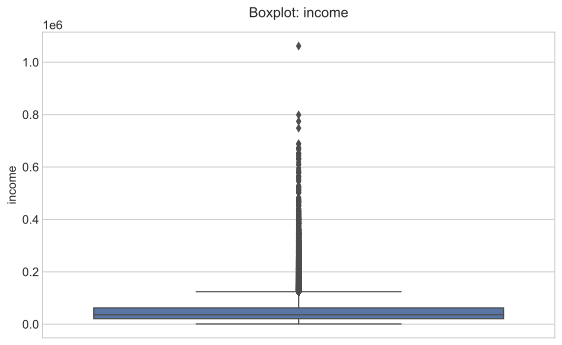

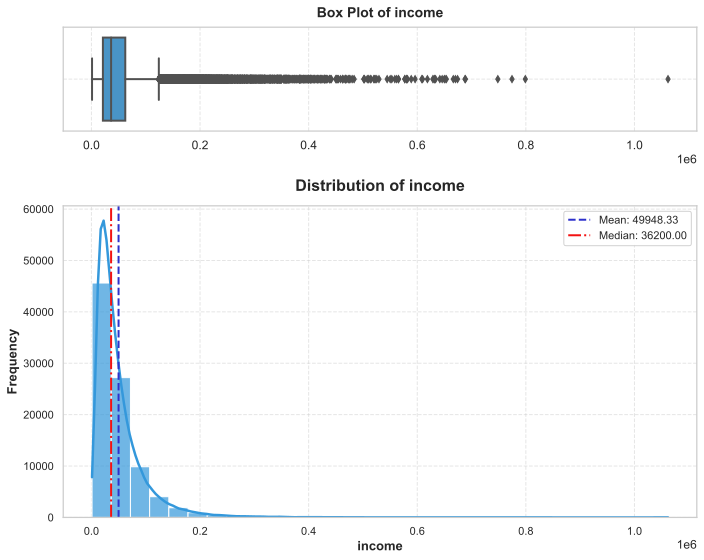

Статистика для 'income':
  Mean:   49948.33
  Median: 36200.00
  Std:    47001.02
  Min:    1100.00
  Max:    1061800.00
  Count:  90700
  Q1:     21100.00
  Q3:     62300.00
  IQR:    41200.00
None


In [17]:
# вывод боксплота до логарифмирования для признака
print(plot_box_and_describe_single(df_preprocessed, 'income'))
# гистограмма income до логарифмирование
print(plot_hist_numeric(df_preprocessed, 'income'))

In [18]:
# логарифмирование признака 
df_preprocessed['log_income'] = np.log1p(df_preprocessed['income'])
# удалим duration из датафремйа, чтоб нивелировать перекос
df_preprocessed = df_preprocessed.drop(columns=['income'])

--- Статистика для 'log_income' ---


count    90700.000000
mean        10.498092
std          0.801539
min          7.003974
25%          9.957076
50%         10.496842
75%         11.039733
max         13.875477
Name: log_income, dtype: float64

Axes(0.0802122,0.0396;0.895038x0.851133)


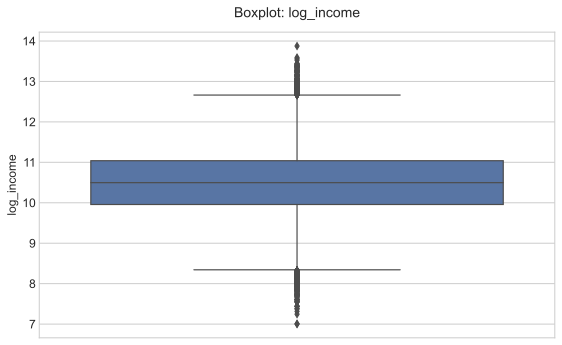

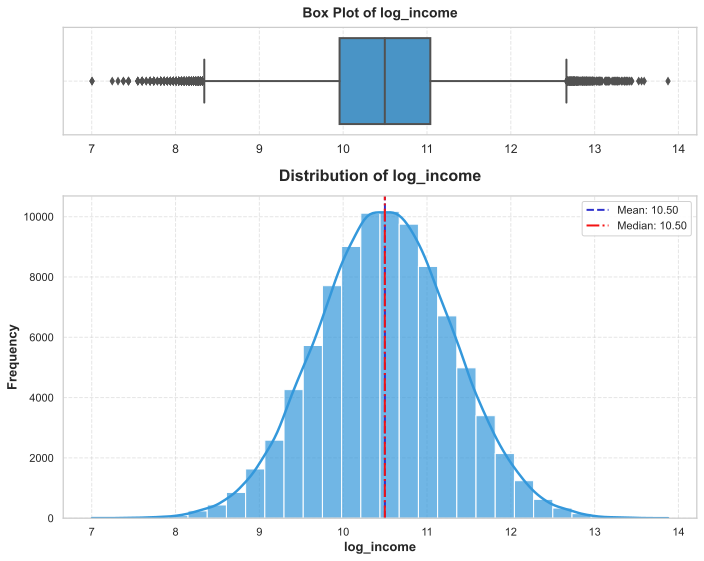

Статистика для 'log_income':
  Mean:   10.50
  Median: 10.50
  Std:    0.80
  Min:    7.00
  Max:    13.88
  Count:  90700
  Q1:     9.96
  Q3:     11.04
  IQR:    1.08
None


In [19]:
# вывод боксплота после логарифмирования для признака
print(plot_box_and_describe_single(df_preprocessed, 'log_income'))
# гистограмма income после логарифмирование
print(plot_hist_numeric(df_preprocessed, 'log_income'))

* Признак income прологарифмирован, удален => новый признак имеет симметричное нормальное распределение...

### **1.1.4 Удаление признака person_id**

In [20]:
# удаление признака
df_preprocessed = df_preprocessed.drop('person_id', axis=1)

### **1.1.5 Работа по признаку sex**

In [21]:
# удалим некорректный класс
df_preprocessed = df_preprocessed[df_preprocessed['sex'] != 'Other']


## **1.2 Разбиение датасета**

In [22]:
# разбиваем признаковое описание на целевой и входные признаки
X = df_preprocessed.drop('annual_medical_cost', axis=1)
y = df_preprocessed['annual_medical_cost']

# разбиваем данные на тренировочную и тестовую выборки
# Разбиваем данные на train и test с соотношением 80 на 20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=SEED 
)

# проверка деления
print(X_train.shape, y_train.shape)
print( X_test.shape, y_test.shape)

(71096, 43) (71096,)
(17775, 43) (17775,)


## **1.3 Индивидуальные преобразования**

In [23]:
# разделим признаки на количесвтенные и качественные признаки
numerical_features = [x for x in df_preprocessed.columns if pd.api.types.is_numeric_dtype(df_preprocessed[x])]
categorical_features = list(set([x for x in df_preprocessed.columns if not pd.api.types.is_numeric_dtype(df_preprocessed[x])]) - set(['deposit']))

# проверка наличия дополнительных признаков
print(numerical_features)
print(categorical_features)

['household_size', 'bmi', 'visits_last_year', 'hospitalizations_last_3yrs', 'days_hospitalized_last_3yrs', 'medication_count', 'systolic_bp', 'diastolic_bp', 'ldl', 'deductible', 'copay', 'policy_term_years', 'policy_changes_last_2yrs', 'provider_quality', 'annual_medical_cost', 'chronic_count', 'hypertension', 'diabetes', 'asthma', 'copd', 'cardiovascular_disease', 'cancer_history', 'kidney_disease', 'liver_disease', 'arthritis', 'mental_health', 'proc_imaging_count', 'proc_surgery_count', 'proc_physio_count', 'proc_consult_count', 'proc_lab_count', 'had_major_procedure', 'log_age', 'log_income']
['employment_status', 'marital_status', 'alcohol_freq', 'urban_rural', 'region', 'network_tier', 'sex', 'education', 'smoker', 'plan_type']


In [24]:
# выведем уникальные значения признаков
for i in categorical_features:
    print(f'Уникальные значения признака {i.upper()}:')
    print(df_preprocessed[i].unique())

Уникальные значения признака EMPLOYMENT_STATUS:
['Employed' 'Self-employed' 'Retired' 'Unemployed']
Уникальные значения признака MARITAL_STATUS:
['Married' 'Single' 'Divorced' 'Widowed']
Уникальные значения признака ALCOHOL_FREQ:
['Weekly' 'Occasional' 'Daily']
Уникальные значения признака URBAN_RURAL:
['Urban' 'Suburban' 'Rural']
Уникальные значения признака REGION:
['North' 'Central' 'West' 'South' 'East']
Уникальные значения признака NETWORK_TIER:
['Gold' 'Silver' 'Platinum' 'Bronze']
Уникальные значения признака SEX:
['Female' 'Male']
Уникальные значения признака EDUCATION:
['No HS' 'Some College' 'Doctorate' 'HS' 'Masters' 'Bachelors']
Уникальные значения признака SMOKER:
['Never' 'Current' 'Former']
Уникальные значения признака PLAN_TYPE:
['POS' 'HMO' 'EPO' 'PPO']


**Представленные качесвтенные признаки кодируем следующим образомб, а количественные признаки стандартизируем:**

* One‑Hot Encoding — для номинальных признаков без порядка: plan_type, sex, region, urban_rural, network_tier, marital_status, employment_status;
* Ordinal Encoding — когда категории можно упорядочить по смыслу/рангу: education, alcohol_freq, smoker;
* Binary (0/1) — для бинарных признаков (yes/no, true/false): hypertension, diabetes, is_high_risk и т.п...

In [25]:
cat_ohe = [
    'sex', 'region', 'urban_rural', 'marital_status',
    'employment_status', 'plan_type'
]

cat_ordinal = ['education', 'alcohol_freq', 'smoker', 'network_tier']
binary_yesno = []

num_scale = [
    'household_size', 'dependents', 'bmi',
    'visits_last_year', 'hospitalizations_last_3yrs',
    'days_hospitalized_last_3yrs', 'medication_count',
    'systolic_bp', 'diastolic_bp', 'ldl', 'hba1c',
    'deductible', 'copay', 'policy_term_years',
    'policy_changes_last_2yrs', 'provider_quality', 'risk_score',
    'annual_premium', 'monthly_premium', 'claims_count',
    'avg_claim_amount', 'total_claims_paid', 'chronic_count',
    'proc_imaging_count', 'proc_surgery_count', 'proc_physio_count',
    'proc_consult_count', 'proc_lab_count', 'log_age', 'log_income',
    'is_high_risk'
]

edu_order = ['No HS', 'HS', 'Some College', 'Bachelors', 'Masters', 'Doctorate']
alc_order = ['Occasional', 'Weekly', 'Daily']
smk_order = ['Never', 'Former', 'Current']
nt_order = ['Bronze', 'Silver', 'Gold', 'Platinum']

In [26]:
def filter_cols(cols, df):
    return [c for c in cols if c in df.columns]


def build_preprocessor(df):
    ohe_cols = filter_cols(cat_ohe, df)
    ord_cols = filter_cols(cat_ordinal, df)
    bin_cols = filter_cols(binary_yesno, df)
    num_cols = filter_cols(num_scale, df)

    ord_cats = []
    for c in ord_cols:
        if c == 'education':
            ord_cats.append(edu_order)
        elif c == 'alcohol_freq':
            ord_cats.append(alc_order)
        elif c == 'smoker':
            ord_cats.append(smk_order)
        elif c == 'network_tier':
            ord_cats.append(nt_order)

    preprocessor = ColumnTransformer(
        transformers=[
            ('ohe', OneHotEncoder(
                drop='first',
                sparse_output=False,
                handle_unknown='ignore'
            ), ohe_cols),

            ('ordinal', OrdinalEncoder(
                categories=ord_cats,
                handle_unknown='use_encoded_value',
                unknown_value=-1
            ), ord_cols),

            ('num', SkPipeline(steps=[
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())
            ]), num_cols)
        ],
        remainder='drop'
    )

    return preprocessor

In [27]:
# функция для создания pipeline
def make_baseline_pipeline(model):
    """
    Создаёт pipeline:
    1. preprocessor — обработка признаков
    2. model — модель с логарифмированием y
    """
    log_model = TransformedTargetRegressor(
        regressor=model,
        func=np.log1p,
        inverse_func=np.expm1
    )

    return SkPipeline(steps=[
        ('preprocessor', build_preprocessor(X_train)),
        ('model', log_model)
    ])

# y_train_log = np.log1p(y_train)
# y_pred = np.expm1(y_pred_log)

# **2. Построение базовой модели (baseline)**

На этапе построения базовой модели (baseline) сознательно отказались от тонкой настройки гиперпараметров и сложных ансамблей. Цель данного этапа — зафиксировать исходную точку качества прогноза, чтобы в дальнейшем корректно оценивать вклад каждого улучшения: новых признаков, методов обработки дисбаланса, подбора параметров и смены архитектуры модели.

In [28]:
# список базовых моделей
baseline_models = [
    (LinearRegression(), "Linear Regression"),

    (DecisionTreeRegressor(
        random_state=42
    ), "Decision Tree"),

    (RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ), "Random Forest"),

    (GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ), "Gradient Boosting")
]

In [29]:
# обучение и оценка
baseline_results = []

for model, model_name in baseline_models:
    print(f"Обучается: {model_name}")

    pipeline = make_baseline_pipeline(model)

    # Обучаем на сырых X_train и y_train
    pipeline.fit(X_train, y_train)

    # Прогноз сразу в исходных деньгах
    y_pred = pipeline.predict(X_test)

    metrics = evaluate_regression(
        y_test=y_test,
        y_pred=y_pred,
        model_name=model_name
    )

    baseline_results.append(metrics)

baseline_results_df = pd.DataFrame(baseline_results)
baseline_results_df

Обучается: Linear Regression

--- Regression Report: Linear Regression ---
MAE:  1063.47
MSE:  2048737.01
RMSE: 1431.34
R²:   0.047
MAPE: 65.33%
----------------------------------------

Обучается: Decision Tree

--- Regression Report: Decision Tree ---
MAE:  1499.39
MSE:  3792183.32
RMSE: 1947.35
R²:   -0.765
MAPE: 101.26%
----------------------------------------

Обучается: Random Forest

--- Regression Report: Random Forest ---
MAE:  1065.65
MSE:  2051538.70
RMSE: 1432.32
R²:   0.045
MAPE: 64.81%
----------------------------------------

Обучается: Gradient Boosting

--- Regression Report: Gradient Boosting ---
MAE:  1054.61
MSE:  2002941.91
RMSE: 1415.25
R²:   0.068
MAPE: 64.85%
----------------------------------------



,Model,MAE,MSE,RMSE,R2,MAPE (%)
0,Linear Regression,1063.467677,2.048737e+06,1431.340984,0.046706,65.333874
1,Decision Tree,1499.392303,3.792183e+06,1947.352901,-0.764534,101.258930
2,Random Forest,1065.652801,2.051539e+06,1432.319342,0.045402,64.810854
3,Gradient Boosting,1054.606273,2.002942e+06,1415.253304,0.068015,64.852764


In [30]:
baseline_results_df.sort_values(by='RMSE')

,Model,MAE,MSE,RMSE,R2,MAPE (%)
3,Gradient Boosting,1054.606273,2.002942e+06,1415.253304,0.068015,64.852764
0,Linear Regression,1063.467677,2.048737e+06,1431.340984,0.046706,65.333874
2,Random Forest,1065.652801,2.051539e+06,1432.319342,0.045402,64.810854
1,Decision Tree,1499.392303,3.792183e+06,1947.352901,-0.764534,101.258930


* MAE ≈ 1650 — в среднем модель ошибается на 1650 единиц (рублей/долларов). Для кого-то это мало, для дорогих кейсов — капля в море.
* RMSE ≈ 2870 — из‑за штрафов за большие ошибки RMSE заметно выше MAE. Значит, есть отдельные случаи, где прогноз сильно «летит мимо».
* R² ≈ 0.10 — модель объясняет примерно 10% разброса расходов. Остальные 90% — это либо шум, либо факторы, которых нет в данных, либо нелинейные эффекты, которые простые модели не ловят.
* MAPE ≈ 73% — в среднем прогноз отклоняется на 73% от факта. Для страховой аналитики это обычно слишком много. Но MAPE особенно «ломается», если у части клиентов расходы близки к нулю: даже небольшая ошибка даёт огромный процент...

# **3. Тюнинг моделей (подбор гиперапараметров моделей)**

* каждый раз передаём в RandomizedSearchCV сырой X_train и y_train. Pipeline сам будет внутри каждого CV-фолда заново обучать препроцессор и логарифмировать цель — это устраняет утечку данных

In [31]:
# функция для создания pipeline
def make_tuning_pipeline(model):
    log_model = TransformedTargetRegressor(
        regressor=model,
        func=np.log1p,
        inverse_func=np.expm1
    )

    return SkPipeline(steps=[
        ('preprocessor', build_preprocessor(X_train)),
        ('model', log_model)
    ])

In [ ]:
tuning_configs = [
    {
        "model_name": "Ridge",
        "model": Ridge(random_state=42),
        "param_distributions": {
            "model__regressor__alpha": [0.1, 1, 10, 100]
        },
        "n_iter": 4
    },

    {
        "model_name": "Decision Tree",
        "model": DecisionTreeRegressor(random_state=42),
        "param_distributions": {
            "model__regressor__max_depth": [5, 10, 15, None],
            "model__regressor__min_samples_leaf": [1, 5, 10, 20]
        },
        "n_iter": 12
    },

    {
        "model_name": "Random Forest",
        "model": RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        ),
        "param_distributions": {
            "model__regressor__n_estimators": [100, 200],
            "model__regressor__max_depth": [10, 20, None],
            "model__regressor__min_samples_leaf": [1, 5, 10],
            "model__regressor__max_features": ["sqrt", 0.5]
        },
        "n_iter": 15
    },

    {
        "model_name": "Gradient Boosting",
        "model": GradientBoostingRegressor(random_state=42),
        "param_distributions": {
            "model__regressor__n_estimators": [100, 200],
            "model__regressor__learning_rate": [0.03, 0.05, 0.1],
            "model__regressor__max_depth": [2, 3, 4],
            "model__regressor__subsample": [0.8, 1.0]
        },
        "n_iter": 15
    }
]

In [33]:
# цикл тюнинга
tuning_results = []
best_models = {}

for config in tuning_configs:
    model_name = config["model_name"]
    model = config["model"]
    param_distributions = config["param_distributions"]
    n_iter = config["n_iter"]

    print(f"\n=== Тюнинг: {model_name} ===")

    pipeline = make_tuning_pipeline(model)

    random_search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions,
        n_iter=n_iter,
        scoring="neg_root_mean_squared_error",
        cv=5,
        random_state=42,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    # ВАЖНО: сырые X_train и y_train
    random_search.fit(X_train, y_train)

    best_models[model_name] = random_search.best_estimator_

    print("Лучшие параметры:")
    print(random_search.best_params_)

    print("Лучший CV RMSE:")
    print(-random_search.best_score_)

    tuning_results.append({
        "model_name": model_name,
        "best_cv_rmse": -random_search.best_score_,
        "best_params": random_search.best_params_
    })

tuning_results_df = pd.DataFrame(tuning_results)
tuning_results_df


=== Тюнинг: Ridge ===
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Лучшие параметры:
{'model__regressor__alpha': 100}
Лучший CV RMSE:
1435.2941037345113

=== Тюнинг: Decision Tree ===
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Лучшие параметры:
{'model__regressor__min_samples_leaf': 10, 'model__regressor__max_depth': 5}
Лучший CV RMSE:
1429.6680109271335

=== Тюнинг: Random Forest ===
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Лучшие параметры:
{'model__regressor__n_estimators': 200, 'model__regressor__min_samples_leaf': 5, 'model__regressor__max_features': 0.5, 'model__regressor__max_depth': 10}
Лучший CV RMSE:
1421.9391926088786

=== Тюнинг: Gradient Boosting ===
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Лучшие параметры:
{'model__regressor__subsample': 1.0, 'model__regressor__n_estimators': 200, 'model__regressor__max_depth': 3, 'model__regressor__learning_rate': 0.1}
Лучший CV RMSE:
1419.2373156653898


,model_name,best_cv_rmse,best_params
0,Ridge,1435.294104,{'model__regressor__alpha': 100}
1,Decision Tree,1429.668011,"{'model__regressor__min_samples_leaf': 10, 'mo..."
2,Random Forest,1421.939193,"{'model__regressor__n_estimators': 200, 'model..."
3,Gradient Boosting,1419.237316,"{'model__regressor__subsample': 1.0, 'model__r..."


In [37]:
tuning_results_df.sort_values(by='best_cv_rmse')

,model_name,best_cv_rmse,best_params
3,Gradient Boosting,1419.237316,"{'model__regressor__subsample': 1.0, 'model__r..."
2,Random Forest,1421.939193,"{'model__regressor__n_estimators': 200, 'model..."
1,Decision Tree,1429.668011,"{'model__regressor__min_samples_leaf': 10, 'mo..."
0,Ridge,1435.294104,{'model__regressor__alpha': 100}


# **5. Тест лучшей модели с подобранными гиперпараметрами**

In [49]:
# тест лучшей модели
best_model_name = "Gradient Boosting"
best_pipeline = best_models[best_model_name]

y_pred = best_pipeline.predict(X_test)

best_model_test_metrics = evaluate_regression(
    y_test=y_test,
    y_pred=y_pred,
    model_name=best_model_name
)

best_model_test_metrics


--- Regression Report: Gradient Boosting ---
MAE:  1054.16
MSE:  2001180.13
RMSE: 1414.63
R²:   0.069
MAPE: 64.83%
----------------------------------------



{'Model': 'Gradient Boosting',
 'MAE': 1054.161058114088,
 'MSE': 2001180.133385244,
 'RMSE': 1414.6307410010727,
 'R2': 0.06883443509189513,
 'MAPE (%)': 64.83382918652403}

Интерпретация метрик качества:
* MAE = 1054.16 — средняя абсолютная ошибка прогноза составляет порядка 1 054 руб. Это означает, что в типичном случае прогноз отклоняется от фактических расходов на указанную сумму. Например, при фактических расходах клиента в 5 000 руб. прогноз модели находится в диапазоне 3 950–6 050 руб. С практической точки зрения это соответствует недооценке или переоценке расходов примерно на одну тысячу рублей.
* RMSE = 1 414.63 — среднеквадратичная ошибка выше MAE, что свидетельствует о наличии отдельных наблюдений с существенными отклонениями прогноза от факта. В частности, модель допускает крупные ошибки на некоторых клиентах (например, прогноз 2 000 руб. при фактических 10 000 руб.), что сильнее влияет на RMSE из‑за квадратичного штрафа.
* R² = 0.069 — модель объясняет около 6.9% дисперсии целевой переменной. Оставшиеся ~93% вариации годовых медицинских расходов обусловлены факторами, не учтёнными в модели, шумом в данных либо сложными нелинейными зависимостями, которые алгоритм пока не смог надёжно выявить. Низкий R² типичен для задач прогнозирования медицинских и страховых расходов из‑за высокой неоднородности затрат между клиентами.
* MAPE = 64.83% — средняя процентная ошибка прогноза составляет 64.83%. Данный показатель следует интерпретировать с осторожностью: из‑за чувствительности MAPE к малым значениям целевой переменной даже небольшие абсолютные отклонения при низких расходах приводят к сильному росту процентной ошибки. Например, прогноз в 170 руб. при фактических расходах 100 руб. даёт ошибку 70%, хотя абсолютная погрешность составляет всего 70 руб. В связи с этим для оценки качества модели приоритетнее использовать MAE и RMSE.

# **Общий вывод**

По результатам тестирования модель градиентного бустинга показывает среднюю абсолютную ошибку на уровне 1 054 руб. (MAE), при этом среднеквадратичная ошибка (RMSE) достигает 1 415 руб., что указывает на наличие отдельных случаев с крупными отклонениями. Коэффициент детерминации R² равен 0.069, что отражает низкую долю объяснённой дисперсии — типичную для задач со скошенным распределением расходов. Процентная ошибка MAPE (64.83%) имеет ограниченное практическое значение из‑за искажений на малых значениях целевой переменной; основной акцент при оценке точности сделан на MAE.